# GEOG0178 Machine Learning Data Analysis Project

Welcome to this notebook!

This project investigated to what extent a country’s innovation performance, measured by the Global Innovation Index (GII), can be predicted from economic indicators.

The project consisted of four parts:
1. **Data Cleaning and Wrangling**: Importing, cleaning, and merging datasets.
2. **Exploratory Data Analysis (EDA)**:  Visualising patterns and relationships in the data.
3. **Modelling**: Applying ML models to understand and predict innovation scores.
4. **Model Results, Performance and Comparison**: Comparing models and drawing conclusions.


# 1. Data Cleaning and Wrangling

In [1]:
# Install the pycountry package to find ISO codes for each country
!pip install pycountry

In [2]:
# Import necessary packages
import pandas as pd
import numpy as np
import pycountry

In [3]:
# Upload the data files
gii_df = pd.read_csv("data/GII.csv")
gii_df.head()

,Country,Year,Rank,Score
0,AGO,2011,-1,-1.00
1,AGO,2012,135,22.20
2,AGO,2013,135,23.46
3,AGO,2014,135,23.82
4,AGO,2015,120,26.20


In [4]:
economy_df = pd.read_csv("data/global_economy_indicators.csv")
economy_df.head()

,CountryID,Country,Year,AMA exchange rate,IMF based exchange rate,Population,Currency,Per capita GNI,"Agriculture, hunting, forestry, fishing (ISIC A-B)",Changes in inventories,...,Household consumption expenditure (including Non-profit institutions serving households),Imports of goods and services,Manufacturing (ISIC D),"Mining, Manufacturing, Utilities (ISIC C-E)",Other Activities (ISIC J-P),Total Value Added,"Transport, storage and communication (ISIC I)","Wholesale, retail trade, restaurants and hotels (ISIC G-H)",Gross National Income(GNI) in USD,Gross Domestic Product (GDP)
0,4,Afghanistan,1970,0.044998,0.044998,10752971,Afghani,164,8.699174e+08,NaN,...,1.551094e+09,195277226.0,370146827.0,376690811.0,127747843.0,1.731454e+09,83917200.0,226387091.0,1.766528e+09,1.731436e+09
1,4,Afghanistan,1971,0.044998,0.044998,11015857,Afghani,168,9.108281e+08,NaN,...,1.675426e+09,276296480.0,387549502.0,394401164.0,133754097.0,1.812857e+09,87860382.0,237019196.0,1.850122e+09,1.812838e+09
2,4,Afghanistan,1972,0.044998,0.044998,11286753,Afghani,149,8.279453e+08,NaN,...,1.498812e+09,290370350.0,352284669.0,358512865.0,121582672.0,1.647918e+09,79864525.0,215477287.0,1.683948e+09,1.647900e+09
3,4,Afghanistan,1973,0.044998,0.044998,11575305,Afghani,150,8.554869e+08,NaN,...,1.508024e+09,262962880.0,364010279.0,370445793.0,125630236.0,1.702735e+09,82528885.0,222624293.0,1.739998e+09,1.702716e+09
4,4,Afghanistan,1974,0.044998,0.044998,11869879,Afghani,177,1.035913e+09,NaN,...,1.778819e+09,305679151.0,440760406.0,448552790.0,152119162.0,2.061752e+09,99918604.0,269525910.0,2.106420e+09,2.061729e+09


In [5]:
# Clean column names and strip country name whitespaces to match with ISO country codes
economy_df.columns = economy_df.columns.str.strip()
economy_df["Country"] = economy_df["Country"].str.strip()

# Convert country names to ISO alpha-3 codes
def get_alpha_3(name):
    try:
        return pycountry.countries.lookup(name).alpha_3
    except:
        return None

economy_df["Country_Code"] = economy_df["Country"].apply(get_alpha_3)

In [6]:
# Drop rows without valid country codes and make a copy
economy_df = economy_df.dropna(subset=["Country_Code"]).copy()
economy_df["Year"] = economy_df["Year"].astype(int)

# Filter to match years
economy_recent = economy_df[economy_df["Year"] >= 2011]

In [7]:
# Merge GII and economy datasets on ISO code and year
gii_df["Year"] = gii_df["Year"].astype(int)
merged_df = pd.merge(
    gii_df,
    economy_recent,
    left_on=["Country", "Year"],
    right_on=["Country_Code", "Year"],
    how="inner"
)

In [8]:
# Display the merged dataframe
merged_df.head()


,Country_x,Year,Rank,Score,CountryID,Country_y,AMA exchange rate,IMF based exchange rate,Population,Currency,...,Imports of goods and services,Manufacturing (ISIC D),"Mining, Manufacturing, Utilities (ISIC C-E)",Other Activities (ISIC J-P),Total Value Added,"Transport, storage and communication (ISIC I)","Wholesale, retail trade, restaurants and hotels (ISIC G-H)",Gross National Income(GNI) in USD,Gross Domestic Product (GDP),Country_Code
0,AGO,2011,-1,-1.00,24,Angola,93.934750,93.934750,24259111,Kwanza,...,4.394741e+10,5.044698e+09,5.361364e+10,2.047049e+10,1.130000e+11,5.311859e+09,1.790042e+10,1.020000e+11,1.120000e+11,AGO
1,AGO,2012,135,22.20,24,Angola,95.467955,95.467955,25188292,Kwanza,...,4.591973e+10,6.089923e+09,5.930386e+10,2.393350e+10,1.310000e+11,5.838182e+09,2.094360e+10,1.180000e+11,1.280000e+11,AGO
2,AGO,2013,135,23.46,24,Angola,96.518279,96.518279,26147002,Kwanza,...,4.930421e+10,7.076055e+09,5.673226e+10,2.688665e+10,1.400000e+11,6.538570e+09,2.506599e+10,1.270000e+11,1.370000e+11,AGO
3,AGO,2014,135,23.82,24,Angola,98.302417,98.302417,27128337,Kwanza,...,5.047163e+10,7.432848e+09,4.903767e+10,2.942261e+10,1.470000e+11,7.182480e+09,3.160851e+10,1.370000e+11,1.460000e+11,AGO
4,AGO,2015,120,26.20,24,Angola,120.060702,120.060702,28127721,Kwanza,...,3.849951e+10,6.955878e+09,3.375070e+10,2.586359e+10,1.160000e+11,6.170380e+09,2.450573e+10,1.130000e+11,1.160000e+11,AGO


In [9]:
# Display row and column size after merging
merged_df.shape

(1562, 30)

In [10]:
# Display null values in each column after merging
merged_df.isnull().sum()

,0
Country_x,0
Year,0
Rank,0
Score,0
CountryID,0
Country_y,0
AMA exchange rate,0
IMF based exchange rate,0
Population,0
Currency,0


In [11]:
# Dropping the columns that are not relevant, non-numeric or have missing values
merged_df = merged_df.drop(columns=[
    "CountryID",
    "Score",
    "Country_x",
    "Currency",
    "Changes in inventories",
    "Country_Code",

]
)

In [12]:
# Dropping rows where Rank = -1 since that denotes invalid data
merged_df = merged_df[merged_df["Rank"] != -1]

In [13]:
merged_df = merged_df.reset_index(drop=True)

In [14]:
# Summary statistics
merged_df.describe()

,Year,Rank,AMA exchange rate,IMF based exchange rate,Population,Per capita GNI,"Agriculture, hunting, forestry, fishing (ISIC A-B)",Construction (ISIC F),Exports of goods and services,Final consumption expenditure,...,Household consumption expenditure (including Non-profit institutions serving households),Imports of goods and services,Manufacturing (ISIC D),"Mining, Manufacturing, Utilities (ISIC C-E)",Other Activities (ISIC J-P),Total Value Added,"Transport, storage and communication (ISIC I)","Wholesale, retail trade, restaurants and hotels (ISIC G-H)",Gross National Income(GNI) in USD,Gross Domestic Product (GDP)
count,1401.000000,1401.000000,1401.000000,1401.000000,1.401000e+03,1401.000000,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,...,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03,1.401000e+03
mean,2015.941470,67.025696,618.783832,614.976770,5.324470e+07,16658.803712,2.475485e+10,3.280997e+10,1.665284e+11,4.445857e+11,...,3.414792e+11,1.627165e+11,9.558489e+10,1.291192e+11,2.569571e+11,5.771730e+11,5.236318e+10,8.113885e+10,6.059135e+11,6.052881e+11
std,3.150193,38.365824,2457.114167,2452.841711,1.743875e+08,20762.010784,9.721157e+10,1.068068e+11,3.726766e+11,1.585315e+12,...,1.264881e+12,3.807868e+11,3.754959e+11,4.585469e+11,1.040757e+12,2.085402e+12,1.975490e+11,2.887691e+11,2.127074e+12,2.099508e+12
min,2011.000000,1.000000,0.275979,0.275979,9.800100e+04,283.000000,3.214679e+07,5.283229e+07,1.771247e+08,1.088334e+09,...,7.690444e+08,3.642986e+08,7.718816e+07,1.027871e+08,1.832218e+08,1.132485e+09,7.429018e+07,1.595327e+08,1.200492e+09,1.229462e+09
25%,2013.000000,34.000000,1.029797,1.029797,4.450644e+06,2529.000000,1.500470e+09,1.115187e+09,6.867142e+09,1.647800e+10,...,1.318299e+10,8.986287e+09,1.902383e+09,3.704751e+09,5.874055e+09,1.782581e+10,1.568690e+09,2.821816e+09,1.859132e+10,1.915706e+10
50%,2016.000000,66.000000,8.850408,8.850408,1.110326e+07,6624.000000,4.376452e+09,3.793778e+09,2.778392e+10,5.172463e+10,...,4.070240e+10,2.919865e+10,7.993778e+09,1.366517e+10,2.372877e+10,6.395979e+10,6.332949e+09,9.226526e+09,6.696784e+10,6.871329e+10
75%,2019.000000,99.000000,119.353558,119.353558,3.515979e+07,22519.000000,1.512277e+10,1.769245e+10,1.450000e+11,2.540000e+11,...,1.950000e+11,1.370000e+11,4.955176e+10,8.136508e+10,1.150000e+11,3.200000e+11,3.004127e+10,4.834788e+10,3.410000e+11,3.460000e+11
max,2021.000000,143.000000,23208.368330,23208.368330,1.425893e+09,103989.000000,1.350000e+12,1.240000e+12,3.530000e+12,1.930000e+13,...,1.590000e+13,3.400000e+12,4.870000e+12,5.780000e+12,1.290000e+13,2.330000e+13,2.490000e+12,3.520000e+12,2.360000e+13,2.330000e+13


In [15]:
# Overview of the dataset
merged_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1401 entries, 0 to 1400
Data columns (total 24 columns):
 #   Column                                                                                    Non-Null Count  Dtype  
---  ------                                                                                    --------------  -----  
 0   Year                                                                                      1401 non-null   int64  
 1   Rank                                                                                      1401 non-null   int64  
 2   Country_y                                                                                 1401 non-null   object 
 3   AMA exchange rate                                                                         1401 non-null   float64
 4   IMF based exchange rate                                                                   1401 non-null   float64
 5   Population                                             

# 2. Exploratory Data Analysis (EDA)

There were 20 columns which could be used as predictor variables, therefore in order to better understand the relationship between each predictor variable and the target, their Pearson correlations with "Rank" were computed.

Correlation of each feature with 'Rank':
Per capita GNI                                                                             -0.745364
Exports of goods and services                                                              -0.467044
Imports of goods and services                                                              -0.442377
General government final consumption expenditure                                           -0.345067
Gross Domestic Product (GDP)                                                               -0.305237
Gross National Income(GNI) in USD                                                          -0.303665
Construction (ISIC F)                                                                      -0.299025
Final consumption expenditure                                                              -0.298209
Total Value Added                                                                          -0.295908
Transport, storage and communication (ISIC I)     

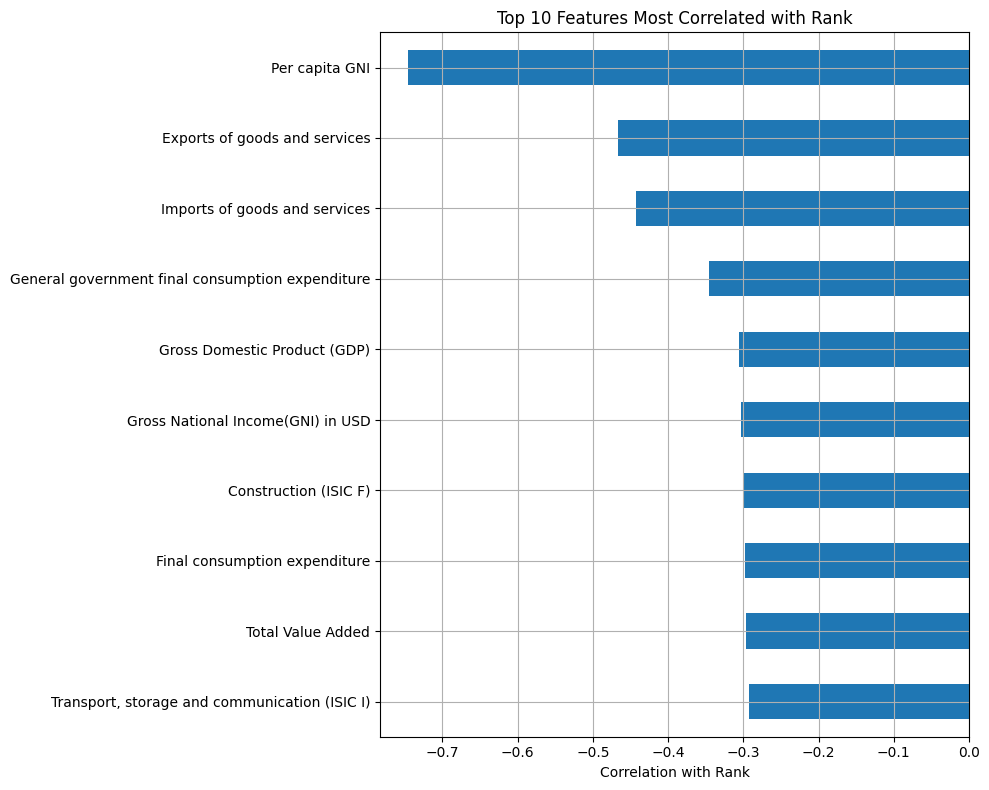

In [16]:
# Calculate Pearson correlation with the target variable "Rank"

# Only selecting numeric columns for the correlation calculation
features = merged_df.select_dtypes(include='number')

# Selecting X and Y variables
X = features.drop(columns=['Rank'])
y = merged_df['Rank']
correlations = X.corrwith(y).sort_values(key=abs, ascending=False)

# Display top correlations
print("Correlation of each feature with 'Rank':")
print(correlations)

# Visualise top correlations as bar chart
import matplotlib.pyplot as plt

correlations.head(10).plot(kind='barh', figsize=(10, 8), title="Top 10 Features Most Correlated with Rank")
plt.gca().invert_yaxis()
plt.xlabel("Correlation with Rank")
plt.tight_layout()
plt.grid(True)
plt.show()

A correlation matrix was computed across all numeric variables in the dataset however, it was visually too overcomplicated and difficult to interpret. Although, we can say that multicollinearity exists across all of the economic indicators besides the AMA exchange rate and IMF based exchange rate columns.

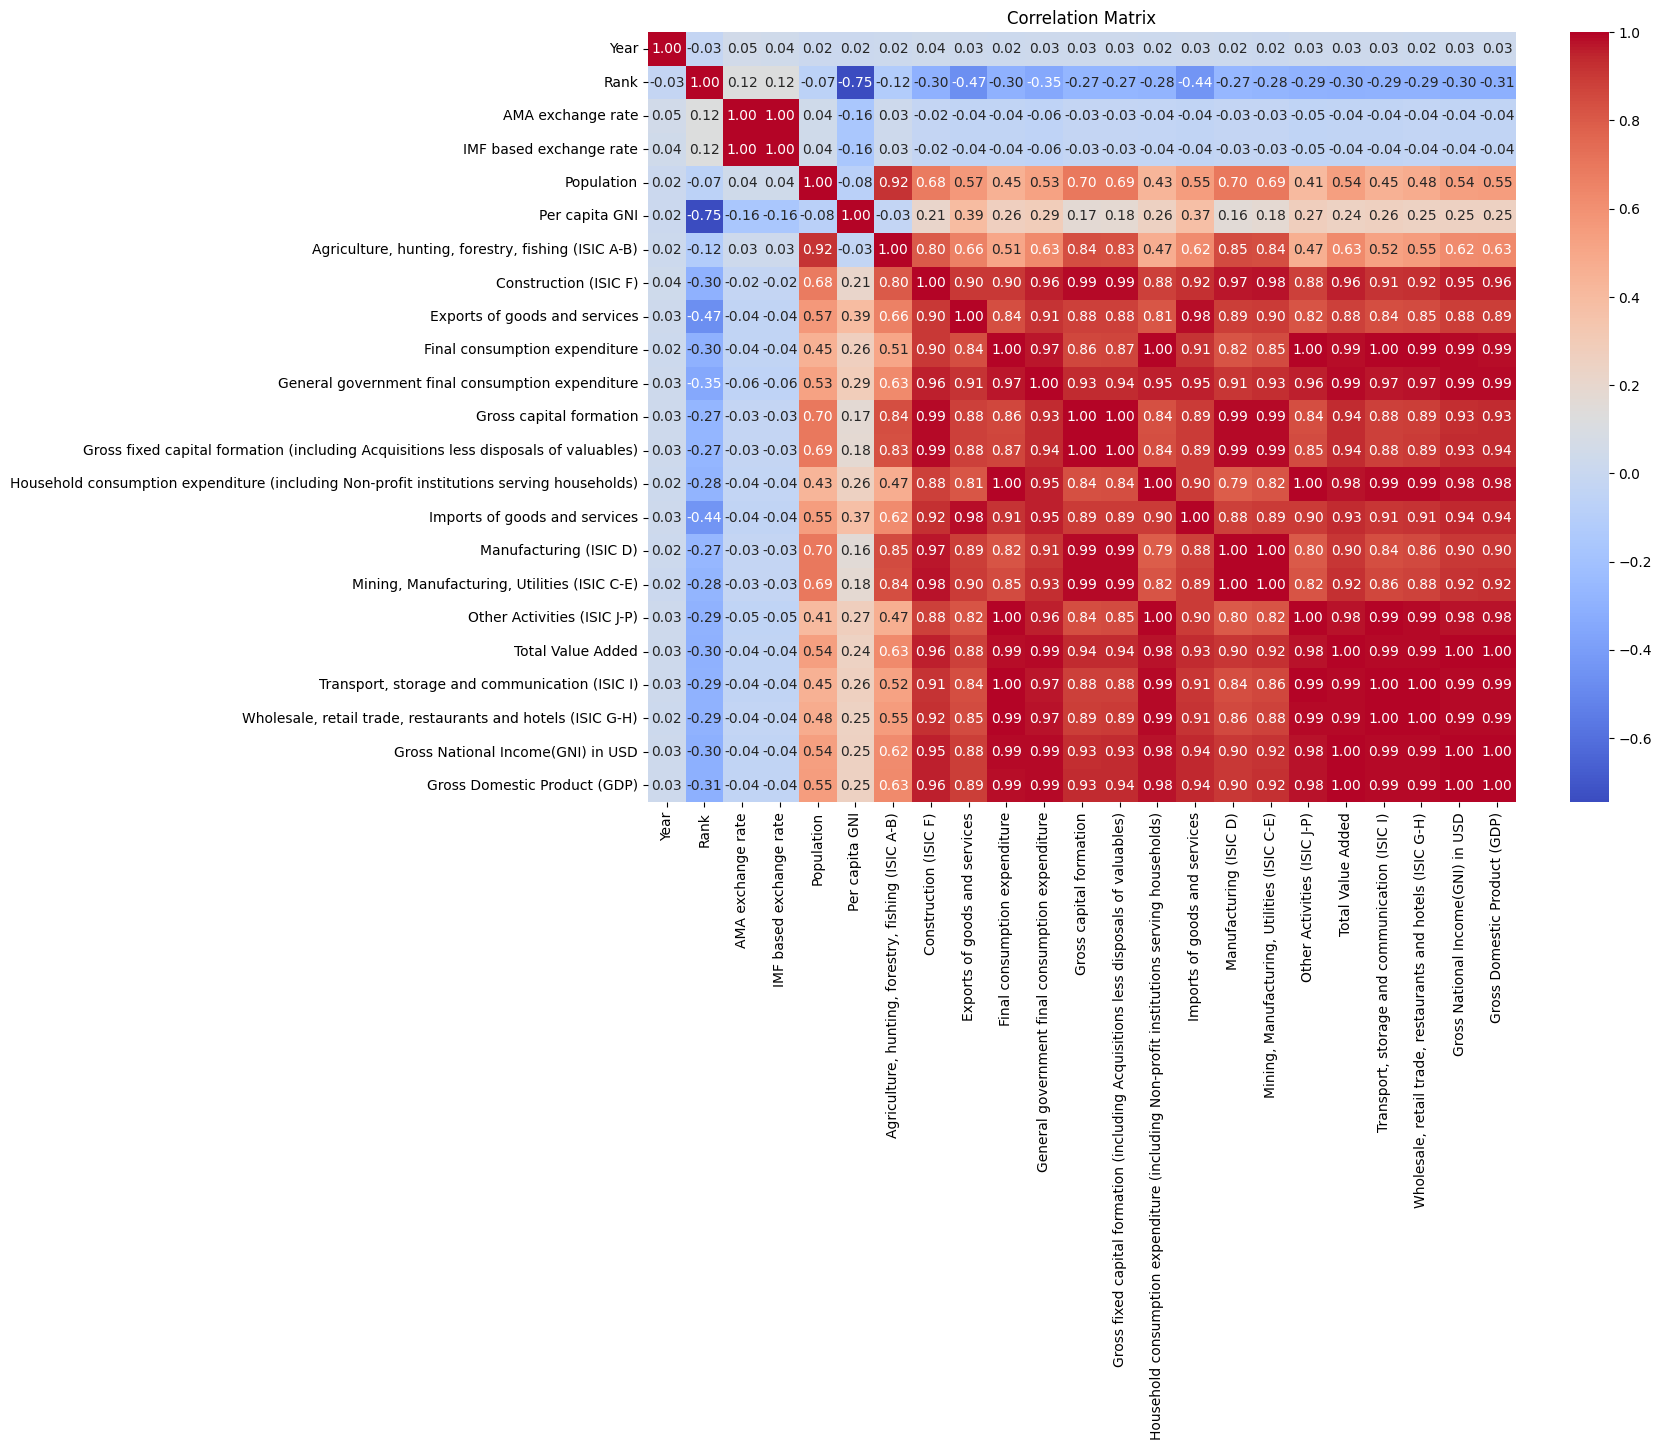

In [17]:
import seaborn as sns
# Select numeric columns
numeric_cols = merged_df.select_dtypes(include=np.number)

# Correlation matrix
plt.figure(figsize=(14, 10))
sns.heatmap(numeric_cols.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

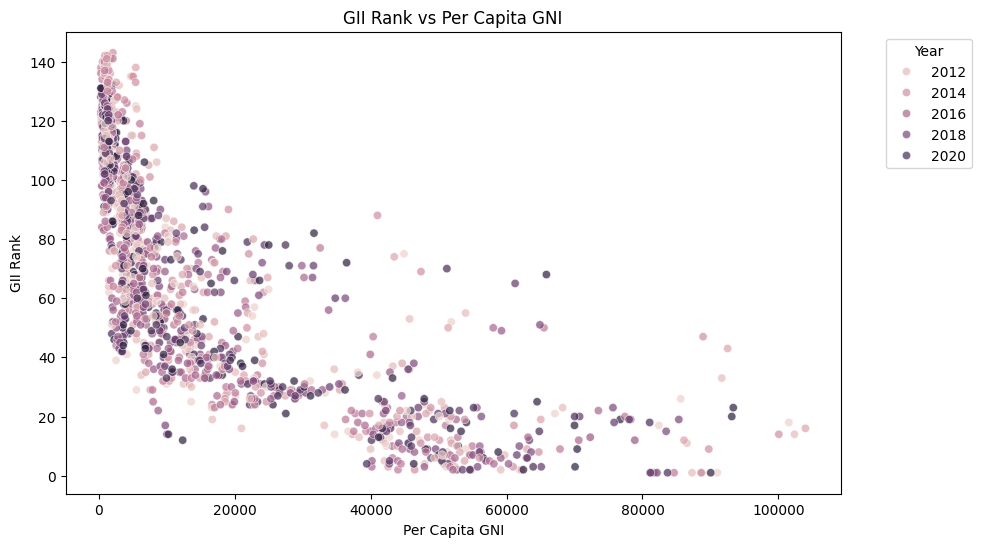

In [18]:
# Plotting the highest correlated indicator against GII Rank to asses the visual relationships
plt.figure(figsize=(10, 6))
sns.scatterplot(data=merged_df, x="Per capita GNI", y="Rank", hue="Year", alpha=0.7)
plt.title("GII Rank vs Per Capita GNI")
plt.xlabel("Per Capita GNI")
plt.ylabel("GII Rank")
plt.legend(title="Year", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

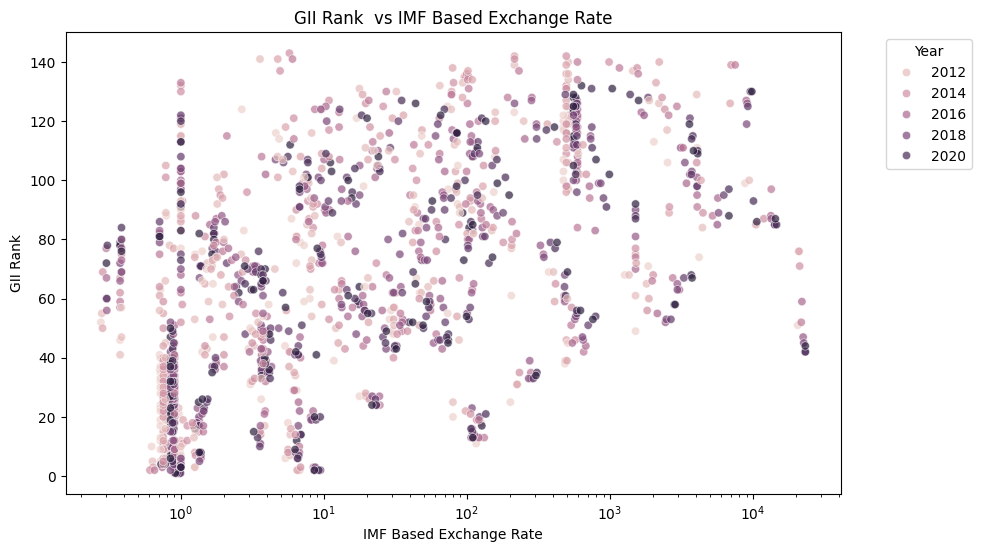

In [19]:
# Plotting GII Rank against IMF based exchange rate which is less correlated to the dependent variable compared to per capita GNI
plt.figure(figsize=(10, 6))
sns.scatterplot(data=merged_df, x="IMF based exchange rate", y="Rank", hue="Year", alpha=0.7)
plt.title("GII Rank  vs IMF Based Exchange Rate")
plt.xlabel("IMF Based Exchange Rate")
plt.ylabel("GII Rank")
plt.xscale("log")  # log scale for better spread
plt.legend(title="Year", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()

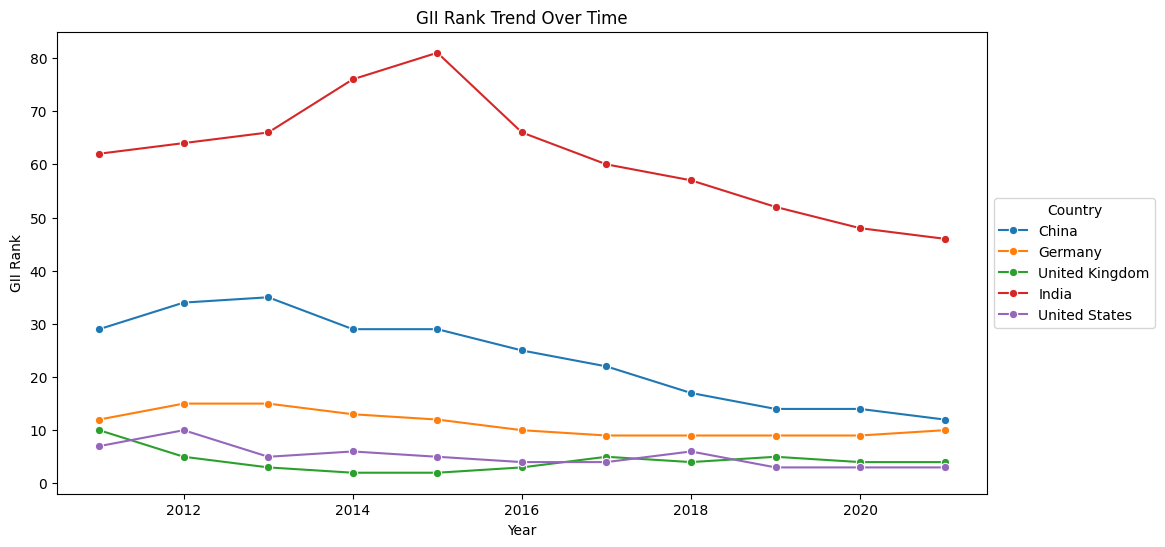

In [20]:
# Evaluating time-series trends of top global economies over time, using a time-series line plot
countries = ["Germany", "India", "United States", "United Kingdom", "China"]
trend_df = merged_df[merged_df["Country_y"].isin(countries)]

plt.figure(figsize=(12, 6))
sns.lineplot(data=trend_df, x="Year", y="Rank", hue="Country_y", marker="o")
plt.title("GII Rank Trend Over Time")
plt.legend(title="Country", loc="center left", bbox_to_anchor=(1, 0.5))
plt.ylabel("GII Rank")
plt.show()

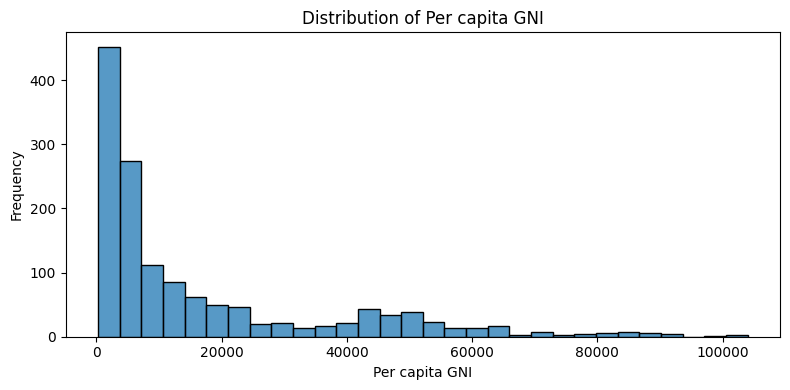

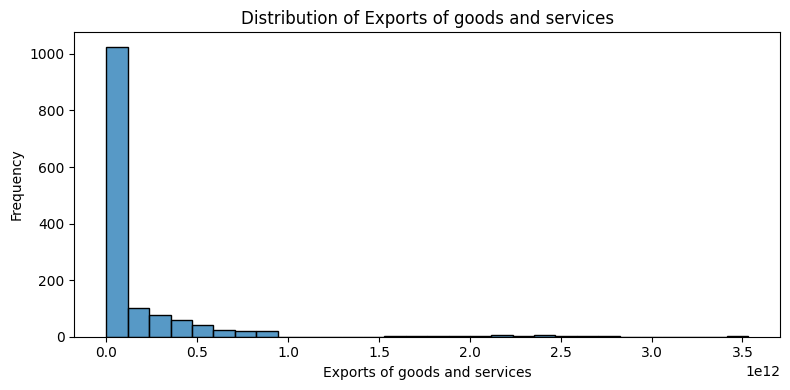

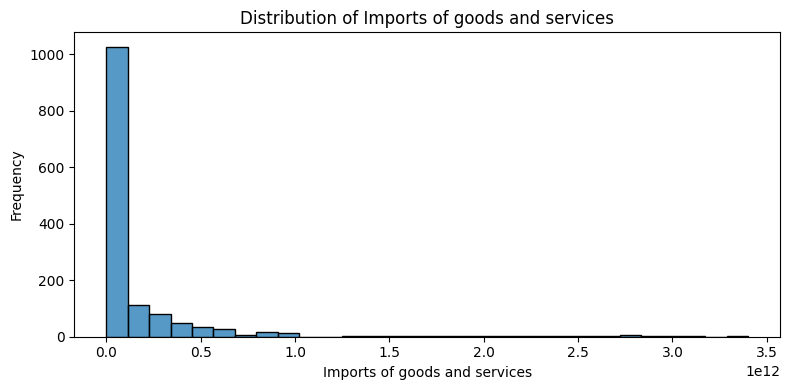

In [21]:
# List of features to assess distributions
features = ["Per capita GNI", "Exports of goods and services", "Imports of goods and services"]

# Plot histograms for each
for feature in features:
    plt.figure(figsize=(8, 4))
    sns.histplot(merged_df[feature], bins=30)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()


# 3. Modelling

In [22]:
# One-hot encode 'Country_y' column and drop original country name column
encoded_df = pd.get_dummies(merged_df, columns=['Country_y'], drop_first=True)

# Define features (X) and target (y)
X = encoded_df.drop(columns=["Rank"])
y = encoded_df["Rank"]

# Split into train and test based on "Year" (8 years of training and 2 years of testing)
X_train = X[X["Year"] < 2019]
X_test = X[X["Year"] >= 2019]
y_train = y[X["Year"] < 2019]
y_test = y[X["Year"] >= 2019]

In [23]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Train Random Forest Regressor
rf = RandomForestRegressor(random_state=42)
rf.fit(X_train, y_train)

# Predict
y_pred_rf = rf.predict(X_test)

In [24]:
# Evaluation function
def evaluate(y_true, y_pred, model_name="Model"):
    mae = mean_absolute_error(y_true, y_pred)
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, y_pred)

    print(f"Evaluation Results for {model_name}")
    print(f"MAE  = {mae:.2f}")
    print(f"RMSE = {rmse:.2f}")
    print(f"R²   = {r2:.3f}")

# Evaluate Random Forest Regressor
evaluate(y_test, y_pred_rf, "Random Forest")

Evaluation Results for Random Forest
MAE  = 6.24
RMSE = 8.53
R²   = 0.948


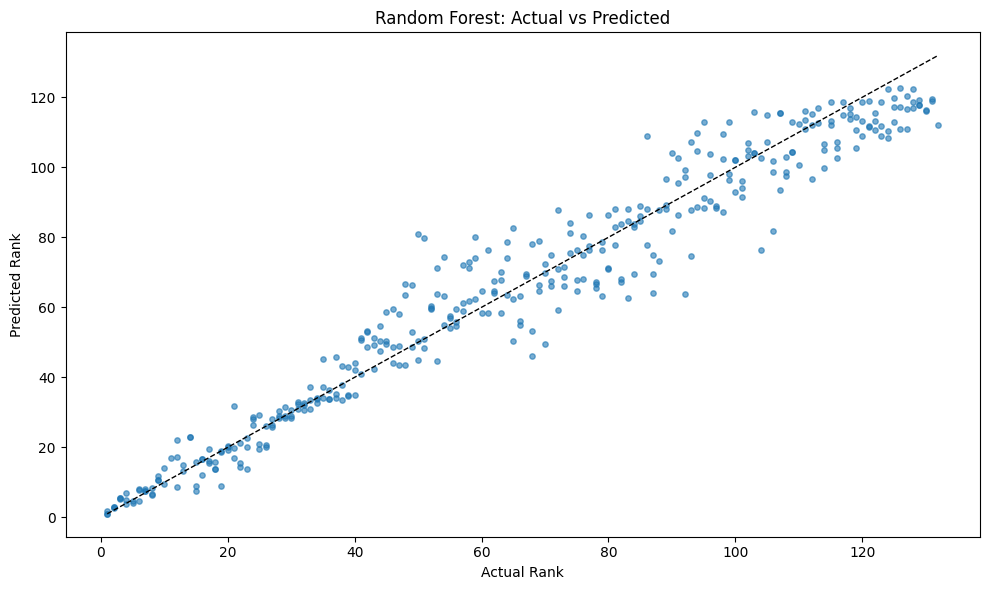

In [25]:
# Actual vs Predicted Plot for the Random Forest Regressor
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred_rf, alpha=0.6, s=15)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=1)
plt.xlabel("Actual Rank")
plt.ylabel("Predicted Rank")
plt.title("Random Forest: Actual vs Predicted")
plt.tight_layout()
plt.show()

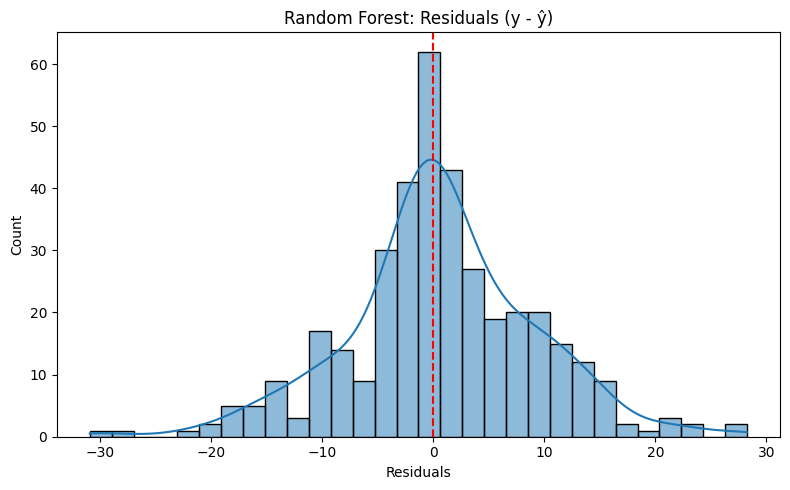

In [26]:
# Residual plot for the Random Forest Regressor
residuals_rf = y_test - y_pred_rf
plt.figure(figsize=(8, 5))
sns.histplot(residuals_rf, kde=True, bins=30)
plt.axvline(0, color='red', linestyle='--')
plt.title("Random Forest: Residuals (y - ŷ)")
plt.xlabel("Residuals")
plt.tight_layout()
plt.show()

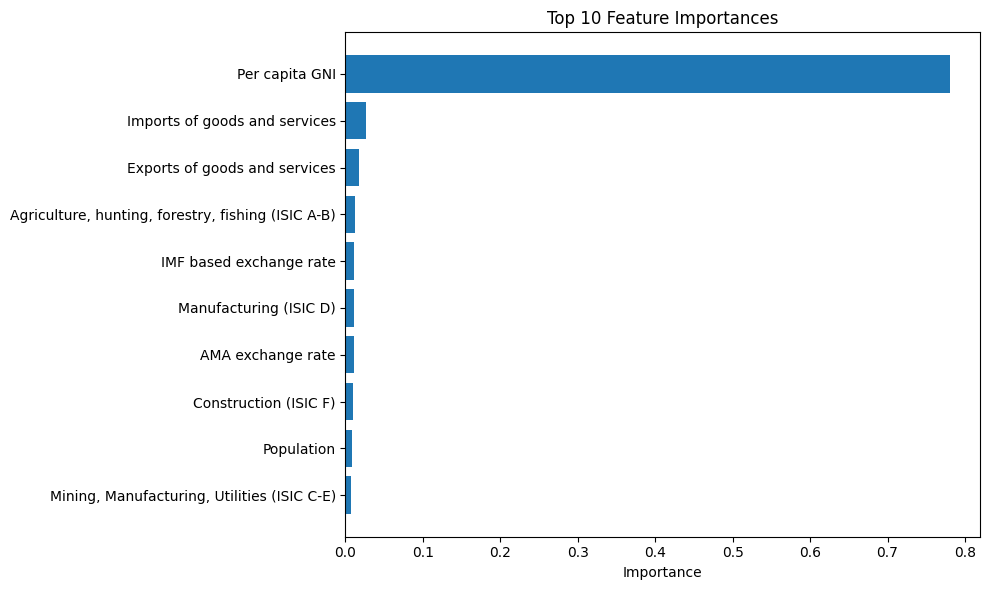

In [27]:
importances = rf.feature_importances_
indices = np.argsort(importances)[-10:]  # Get indices of top 10 features
feature_names = X.columns

plt.figure(figsize=(10, 6))
plt.barh(range(len(indices)), importances[indices], align="center")
plt.yticks(range(len(indices)), [feature_names[i] for i in indices])
plt.xlabel("Importance")
plt.title("Top 10 Feature Importances")
plt.tight_layout()
plt.show()


<b>Understanding Learning in Neural Networks</b><br>
MLPs use backpropagation and gradient descent to iteratively minimise a loss function. Gradients are propagated backward from the output to update the weights layer by layer, optimising the model’s performance over time.

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor

# Create a pipeline with scaling
nn_pipeline = make_pipeline(
    StandardScaler(),
    MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42)
)

# Fit and predict
nn_pipeline.fit(X_train, y_train)
y_pred_nn = nn_pipeline.predict(X_test)

# Evaluate
evaluate(y_test, y_pred_nn, "Neural Network")

Evaluation Results for Neural Network
MAE  = 7.64
RMSE = 9.76
R²   = 0.932


# 4. Model Results, Performance and Comparison

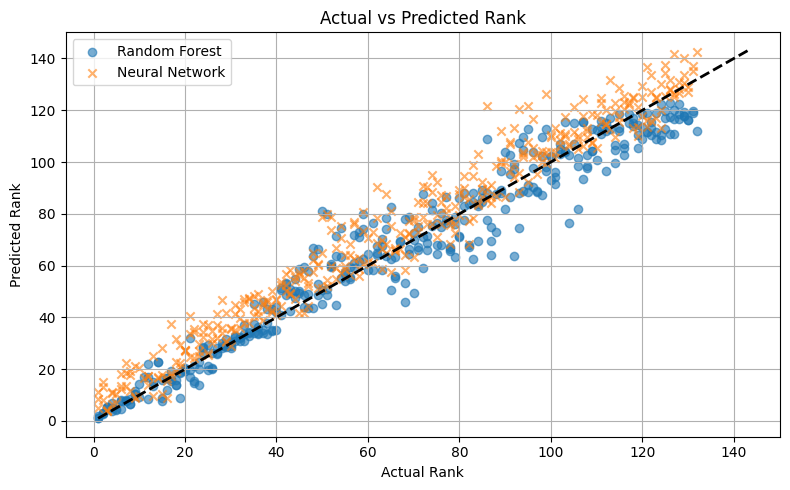

In [29]:
plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred_rf, alpha=0.6, label="Random Forest")
plt.scatter(y_test, y_pred_nn, alpha=0.6, label="Neural Network", marker="x")
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'k--', lw=2)
plt.xlabel("Actual Rank")
plt.ylabel("Predicted Rank")
plt.title("Actual vs Predicted Rank")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [30]:
results = {
    "Model": ["Random Forest", "Neural Network"],
    "MAE": [
        mean_absolute_error(y_test, y_pred_rf),
        mean_absolute_error(y_test, y_pred_nn),
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_rf)),
        np.sqrt(mean_squared_error(y_test, y_pred_nn)),
    ],
    "R²": [
        r2_score(y_test, y_pred_rf),
        r2_score(y_test, y_pred_nn),
    ]
}

comparison_df = pd.DataFrame(results)
comparison_df

,Model,MAE,RMSE,R²
0,Random Forest,6.23840,8.529506,0.948311
1,Neural Network,7.63979,9.758935,0.932336


The Random Forest Regressor outperformed the Multi-layer Perceptron across all evaluation metrics.